# Этап 5. Проверка выводов на новых данных

**Вопрос этапа:** подтверждаются ли выводы этапа 3 (S1 - лучшая при каждом шоке и устойчивая для всех шоков; ранжирование стратегий) на данных, которые при выборе не использовались. Финалистов выбирали на seed пулов `levels` и `robust` и на 40 точках неопределённости этапа 3; если они хороши только «на своих» данных (проклятие победителя), это проявится здесь.

Правила оформления: вывод на экран - на английском; русский - только markdown и комментарии; ячейки дольше 10 минут помечены `# WARNING`.

## Две проверки (подтверждены)

| | Что | Объём | Время |
|---|---|---|---|
| **V1** | 11 стратегий × 3 шока × 10 новых seed (пул `validation`, seed 1–10), номинальные параметры | 330 прогонов | ~45 мин |
| **V2** | 11 стратегий × 20 новых точек неопределённости × 3 шока × 1 новый seed (пул `validation`, seed 11) | 660 прогонов | ~1.5 ч |

* **V1** проверяет устойчивость к случайности при номинальных параметрах: держится ли ранжирование и значимы ли разницы между S1 и ближайшими конкурентами (S9 - без потолка, S4 и S6 - лучшие при сильном шоке). Разницы считаются парно по seed (одинаковые seed у всех стратегий), с 95%-м доверительным интервалом.
* **V2** - проверка вне выборки: новый латинский гиперкуб по тем же пяти параметрам и в тех же диапазонах, но с другим генератором, то есть сценарии, которых не было на этапе 3. Те же метрики, что на этапе 3 (нормировка по 11 стратегиям внутри сценария, 90-й процентиль оценки, доля сценариев, где выполнены все пороги), и те же правила ответов.

Стратегии и пороги берутся из `robust_summary.json` без изменений.

## 5.0. Окружение

In [1]:
import json, hashlib, itertools, math, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, cdist
from scipy import stats

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import abm_runner as ar
import batch_runner as br

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRAY = "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})

NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path("refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")

PREP  = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))
SCRS  = json.loads((OUT_DIR / "screening_summary.json").read_text(encoding="utf-8"))
RBS   = json.loads((OUT_DIR / "robust_summary.json").read_text(encoding="utf-8"))
SEEDS = json.loads((OUT_DIR / "seeds.json").read_text(encoding="utf-8"))["pools"]
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert sha == PREP["model_sha256"], "Model file changed after stage 0 - results are not comparable. Stop."
print("Model unchanged since stage 0:", sha[:16], "| NetLogo", PREP["netlogo_version"])

# --- решения этапа 5 ---
SHOCKS    = PREP["shock_levels"]
SEEDS_V1  = SEEDS["validation"][:10]
SEED_V2   = SEEDS["validation"][10]
N_V2      = 20
LHS_SEED  = 20261122                 # другой генератор, чем на этапе 3 (20261121)
UNC       = RBS["unc_ranges"]
UNC_NAMES = list(UNC)
THRESH    = RBS["thresholds"]
C3_NOM    = RBS["c3_nominal"]
STRATS    = RBS["strategies"]        # S1..S9, none, L2_only
NAMES     = list(STRATS)
FIN       = [s for s in NAMES if s not in ("none", "L2_only")]
N_CARS    = PREP["constants"]["n-consumers"]
K5_BG     = SCRS["k5_background"]
ROBUST    = RBS["robust_strategy"]["strategy"]
RIVALS    = [s for s in ["S9", "S4", "S6"] if s != ROBUST]

used = set(SEEDS["levels"]) | set(SEEDS["robust"]) | set(SEEDS["screening"]) | set(SEEDS["pilot"]) | set(SEEDS["diag"])
assert not (set(SEEDS_V1) | {SEED_V2}) & used, "validation seeds overlap with seeds used earlier"
N_WORKERS = RBS["n_workers"]
CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()), "jvmargs": ["-Xmx512m"],
       "jvm_path": ar.find_jvm(NETLOGO_HOME), "horizon": PREP["horizon"], "checkpoints": PREP["checkpoints"],
       "interface_defaults": PREP["interface_defaults"], "nominal_uncertain": PREP["nominal_uncertain"]}
print("V1 seeds:", SEEDS_V1, "| V2 seed:", SEED_V2, "| robust strategy from stage 3:", ROBUST, "| rivals:", RIVALS)

Model unchanged since stage 0: 2b246166dc0c1182 | NetLogo 7.0.4
V1 seeds: [379, 840, 676, 490, 279, 117, 405, 789, 567, 266] | V2 seed: 102 | robust strategy from stage 3: S1 | rivals: ['S9', 'S4', 'S6']


## 5.1. Задания

Точки V2 строятся тем же способом maximin LHS, что на этапе 3, но с другим генератором. Ячейка показывает минимальное расстояние от новых точек до точек этапа 3 (в нормированных единицах): новые сценарии не совпадают со старыми.

In [2]:
def lhs_maximin(n, d, rng, n_cand=500):
    best, best_d = None, -1
    for _ in range(n_cand):
        u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in range(d)])
        dmin = pdist(u).min()
        if dmin > best_d:
            best, best_d = u, dmin
    return best

u = lhs_maximin(N_V2, len(UNC_NAMES), np.random.default_rng(LHS_SEED))
VPTS = pd.DataFrame({k: UNC[k][0] + u[:, i] * (UNC[k][1] - UNC[k][0]) for i, k in enumerate(UNC_NAMES)})
VPTS.insert(0, "u_id", [f"V{i + 1:02d}" for i in range(N_V2)])
VPTS.to_csv(OUT_DIR / "design_validation_points.csv", index=False, encoding="utf-8-sig")

old = pd.read_csv(OUT_DIR / "design_robust_points.csv")
norm = lambda df: np.column_stack([(df[k] - UNC[k][0]) / (UNC[k][1] - UNC[k][0]) for k in UNC_NAMES])
dist = cdist(norm(VPTS), norm(old)).min(axis=1)
print(f"V2 points: {N_V2}; distance to nearest stage-3 point: min {dist.min():.3f}, median {np.median(dist):.3f}")

def job(stage, s, shock, seed, unc=None, u_id="nominal"):
    tag = f"{u_id}|" if unc else ""
    return {"run_id": f"{stage}|{s}|{tag}sd={shock}|seed={seed}", "stage": stage, "strategy": s, "u_id": u_id,
            "shock": shock, "seed": int(seed), "params": STRATS[s]["params"] | {"shock-depth": shock}, "uncertain": unc}

JOBS_V1 = [job("valid1", s, sh, sd) for sd in SEEDS_V1 for sh in SHOCKS for s in NAMES]
JOBS_V2 = [job("valid2", s, sh, SEED_V2, {k: float(r[k]) for k in UNC_NAMES}, r["u_id"])
           for _, r in VPTS.iterrows() for sh in SHOCKS for s in NAMES]
for jobs in (JOBS_V1, JOBS_V2):
    assert len({j["run_id"] for j in jobs}) == len(jobs)
sec = RBS["sec_per_run_mean"]
print(f"V1 jobs: {len(JOBS_V1)} (~{len(JOBS_V1) * sec / N_WORKERS / 60:.0f} min) | "
      f"V2 jobs: {len(JOBS_V2)} (~{len(JOBS_V2) * sec / N_WORKERS / 60:.0f} min) on {N_WORKERS} workers")

V2 points: 20; distance to nearest stage-3 point: min 0.128, median 0.370
V1 jobs: 330 (~46 min) | V2 jobs: 660 (~92 min) on 2 workers


## 5.2. Запуск

Две ячейки, по отдельному файлу на проверку. При обрыве ячейку просто запустить снова. Пока идут прогоны, ноутбук этапа 4 можно открывать и запускать - он лёгкий.

In [3]:
# WARNING This cell takes approximately 45 minutes to run (330 runs on 2 workers)
link = ar.make_link(CFG) if N_WORKERS == 1 else None
R1 = br.run_jobs(JOBS_V1, CFG, OUT_DIR / "validation_v1.csv", n_workers=N_WORKERS, link=link, log_every=60)

09:59:12 start: 330 runs, workers: 2
10:00:24 3/330 | 1 min | 151 runs/h | ETA ~130 min | errors 0
10:01:30 11/330 | 2 min | 286 runs/h | ETA ~67 min | errors 0
10:02:40 19/330 | 3 min | 328 runs/h | ETA ~57 min | errors 0
10:03:49 25/330 | 5 min | 324 runs/h | ETA ~56 min | errors 0
10:04:52 32/330 | 6 min | 339 runs/h | ETA ~53 min | errors 0
10:05:56 37/330 | 7 min | 330 runs/h | ETA ~53 min | errors 0
10:06:58 43/330 | 8 min | 332 runs/h | ETA ~52 min | errors 0
10:07:59 49/330 | 9 min | 335 runs/h | ETA ~50 min | errors 0
10:09:03 54/330 | 10 min | 329 runs/h | ETA ~50 min | errors 0
10:10:13 60/330 | 11 min | 327 runs/h | ETA ~50 min | errors 0
10:11:13 67/330 | 12 min | 334 runs/h | ETA ~47 min | errors 0
10:12:14 74/330 | 13 min | 340 runs/h | ETA ~45 min | errors 0
10:13:20 82/330 | 14 min | 348 runs/h | ETA ~43 min | errors 0
10:14:22 89/330 | 15 min | 352 runs/h | ETA ~41 min | errors 0
10:15:30 95/330 | 16 min | 350 runs/h | ETA ~40 min | errors 0
10:16:44 103/330 | 18 min 

In [4]:
# WARNING This cell takes approximately 90 minutes to run (660 runs on 2 workers)
R2 = br.run_jobs(JOBS_V2, CFG, OUT_DIR / "validation_v2.csv", n_workers=N_WORKERS, link=link, log_every=60)

10:52:48 start: 660 runs, workers: 2
10:53:55 5/660 | 1 min | 269 runs/h | ETA ~146 min | errors 0
10:54:55 11/660 | 2 min | 311 runs/h | ETA ~125 min | errors 0
10:55:57 16/660 | 3 min | 305 runs/h | ETA ~127 min | errors 0
10:57:16 24/660 | 4 min | 322 runs/h | ETA ~119 min | errors 0
10:58:18 29/660 | 5 min | 316 runs/h | ETA ~120 min | errors 0
10:59:20 34/660 | 7 min | 312 runs/h | ETA ~120 min | errors 0
11:00:21 43/660 | 8 min | 342 runs/h | ETA ~108 min | errors 0
11:01:32 51/660 | 9 min | 350 runs/h | ETA ~104 min | errors 0
11:02:37 57/660 | 10 min | 348 runs/h | ETA ~104 min | errors 0
11:03:40 64/660 | 11 min | 353 runs/h | ETA ~101 min | errors 0
11:04:50 72/660 | 12 min | 359 runs/h | ETA ~98 min | errors 0
11:05:57 79/660 | 13 min | 360 runs/h | ETA ~97 min | errors 0
11:07:03 84/660 | 14 min | 354 runs/h | ETA ~98 min | errors 0
11:08:12 90/660 | 15 min | 350 runs/h | ETA ~98 min | errors 0
11:09:15 95/660 | 16 min | 346 runs/h | ETA ~98 min | errors 0
11:10:18 100/660 

## 5.3. Оценка - тем же способом, что на этапе 3

Сценарий V1 = шок × seed (10 сценариев на шок), сценарий V2 = точка × шок (20 сценариев на шок). В каждом сценарии каждая ось нормируется min–max по 11 стратегиям; `score` - среднее четырёх нормированных осей; K0 и K4 - относительно «без мер» в том же сценарии; пороги - как на этапе 3.

In [5]:
AXES = ["K0", "K4", "K5_excess", "COST"]

def score_frame(df, key):
    df = df.copy()
    df["K5_excess"] = (df.K5_hours - K5_BG) / N_CARS
    df["COST"] = df.K2 + C3_NOM * df.K3_volume
    none = df.loc[df.strategy == "none", key + ["K0", "K4"]].rename(columns={"K0": "K0_none", "K4": "K4_none"})
    df = df.merge(none, on=key, how="left")
    df["K0_rel"] = df.K0 / df.K0_none.clip(lower=1)
    df["K4_rel"] = df.K4 / df.K4_none
    g = df.groupby(key)
    for a in AXES:
        lo, hi = g[a].transform("min"), g[a].transform("max")
        df["n_" + a] = ((df[a] - lo) / (hi - lo).replace(0, np.nan)).fillna(0)
    df["score"] = df[["n_" + a for a in AXES]].mean(axis=1)
    df["score_regret"] = df.score - df.groupby(key).score.transform("min")
    df["pass_all"] = ((df.K0_rel <= THRESH["K0_rel"]) & (df.K4_rel <= THRESH["K4_rel"]) &
                      (df.K5_excess <= THRESH["K5_excess"]) & (df.COST <= THRESH["COST"]))
    return df

def complete(df, key):
    n = df.groupby(key).strategy.nunique()
    keep = n[n == len(NAMES)].index
    return df.set_index(key).loc[keep].reset_index()

R1 = br.read_results(OUT_DIR / "validation_v1.csv")
R2 = br.read_results(OUT_DIR / "validation_v2.csv")
V1 = score_frame(complete(R1[R1.run_id.str.startswith("valid1|")], ["shock", "seed"]), ["shock", "seed"])
V2 = score_frame(complete(R2[R2.run_id.str.startswith("valid2|")], ["u_id", "shock", "seed"]), ["u_id", "shock", "seed"])
print(f"V1: {len(V1)} runs in {V1.groupby(['shock', 'seed']).ngroups} complete scenarios | "
      f"V2: {len(V2)} runs in {V2.groupby(['u_id', 'shock']).ngroups} complete scenarios")
print(f"run time: V1 mean {R1.sec.mean():.1f} s, V2 mean {R2.sec.mean():.1f} s")
V1.to_csv(OUT_DIR / "validation_v1_scored.csv", index=False, encoding="utf-8-sig")
V2.to_csv(OUT_DIR / "validation_v2_scored.csv", index=False, encoding="utf-8-sig")

V1: 330 runs in 30 complete scenarios | V2: 660 runs in 60 complete scenarios
run time: V1 mean 19.3 s, V2 mean 21.8 s


## 5.4. V1: ранжирование на новых seed при номинальных параметрах

Средняя оценка каждой стратегии по 10 seed с 95%-м доверительным интервалом; для сравнения - ранг на этапе 3 (средняя оценка по 80 сценариям с неопределённостью) и ранговая корреляция Спирмена между этапами. Высокая корреляция = порядок стратегий не случайность конкретных seed.


=== shock-depth = 0.2 | best finalist in V1: S3 | Spearman rank correlation with stage 3: 0.95 ===


,score_mean,score_ci95,K0_rel,K4_rel,K5_excess,COST,pass_share,rank_V1,score_mean_stage3,rank_stage3
strategy,,,,,,,,,,
S3,0.130,0.020,0.000,0.237,0.030,65317.268,1.0,1.0,0.112,2.0
S1,0.131,0.020,0.001,0.234,0.036,65728.142,1.0,2.0,0.109,1.0
S2,0.147,0.021,0.001,0.109,0.124,97180.794,1.0,3.0,0.128,4.0
S6,0.149,0.020,0.000,0.215,0.046,93615.689,1.0,4.0,0.132,5.0
S8,0.149,0.021,0.000,0.189,0.067,94989.471,1.0,5.0,0.120,3.0
S9,0.152,0.018,0.001,0.211,0.058,94101.173,1.0,6.0,0.133,6.0
S5,0.167,0.020,0.000,0.288,-0.003,111856.755,1.0,7.0,0.172,8.0
S4,0.187,0.021,0.000,0.143,0.103,151555.462,1.0,8.0,0.165,7.0
L2_only,0.289,0.067,0.182,0.626,0.244,0.000,0.2,9.0,0.352,9.0



=== shock-depth = 0.45 | best finalist in V1: S1 | Spearman rank correlation with stage 3: 0.94 ===


,score_mean,score_ci95,K0_rel,K4_rel,K5_excess,COST,pass_share,rank_V1,score_mean_stage3,rank_stage3
strategy,,,,,,,,,,
S1,0.150,0.017,0.030,0.145,0.214,169302.222,1.0,1.0,0.164,1.0
S9,0.180,0.025,0.010,0.212,0.367,166244.333,1.0,2.0,0.198,3.0
S8,0.184,0.016,0.020,0.078,0.438,203054.579,1.0,3.0,0.180,2.0
S6,0.186,0.020,0.020,0.229,0.436,145736.197,1.0,4.0,0.199,4.0
S4,0.218,0.022,0.020,0.234,0.410,201659.178,1.0,5.0,0.232,5.0
S2,0.219,0.027,0.070,0.041,0.726,187037.874,0.8,6.0,0.235,6.0
L2_only,0.302,0.036,0.207,0.649,0.655,0.000,0.0,7.0,0.327,8.0
S3,0.316,0.050,0.107,0.118,2.066,124108.731,0.7,8.0,0.330,9.0
S5,0.338,0.039,0.054,0.193,3.080,107233.579,0.9,9.0,0.350,10.0



=== shock-depth = 0.7 | best finalist in V1: S9 | Spearman rank correlation with stage 3: 0.94 ===


,score_mean,score_ci95,K0_rel,K4_rel,K5_excess,COST,pass_share,rank_V1,score_mean_stage3,rank_stage3
strategy,,,,,,,,,,
S9,0.165,0.006,0.071,0.248,2.383,169624.082,0.9,1.0,0.196,3.0
S4,0.169,0.005,0.108,0.195,2.305,194453.244,0.4,2.0,0.196,2.0
S1,0.184,0.007,0.140,0.097,1.578,259860.405,0.1,3.0,0.190,1.0
S8,0.197,0.008,0.102,0.042,2.699,306467.315,0.1,4.0,0.203,4.0
S6,0.204,0.044,0.387,0.210,27.806,144610.491,0.0,5.0,0.248,5.0
L2_only,0.227,0.005,0.619,0.730,2.436,0.000,0.0,6.0,0.306,7.0
S7,0.279,0.003,0.011,0.127,2.267,418874.592,0.0,7.0,0.286,6.0
none,0.329,0.006,1.000,1.000,5.807,0.000,0.0,8.0,0.439,9.0
S2,0.391,0.023,1.762,0.021,87.457,195488.229,0.0,9.0,0.357,8.0


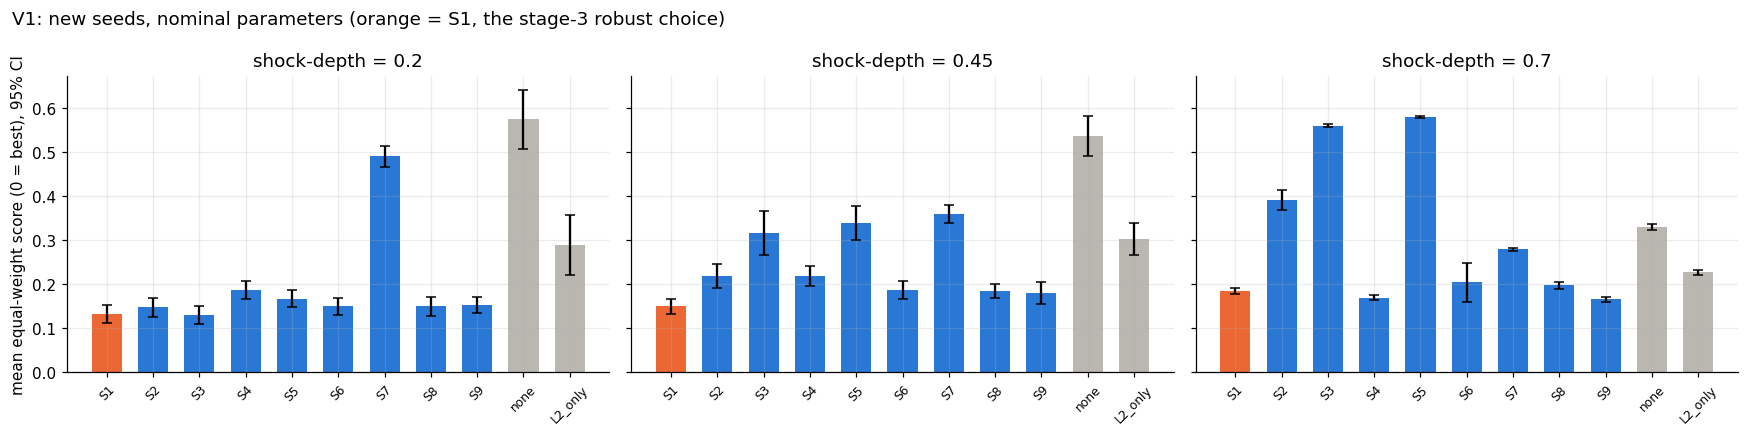

In [6]:
def ci95(x):
    x = np.asarray(x, float)
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

ST3 = br.read_results(OUT_DIR / "robust_summary_table.csv")
rows = []
for (sh, s), d in V1.groupby(["shock", "strategy"]):
    rows.append({"shock": sh, "strategy": s, "score_mean": d.score.mean(), "score_ci95": ci95(d.score),
                 "K0_rel": d.K0_rel.mean(), "K4_rel": d.K4_rel.mean(), "K5_excess": d.K5_excess.mean(),
                 "COST": d.COST.mean(), "pass_share": d.pass_all.mean()})
T1 = pd.DataFrame(rows)
T1["rank_V1"] = T1.groupby("shock").score_mean.rank()
T1 = T1.merge(ST3[["shock", "strategy", "score_mean"]].rename(columns={"score_mean": "score_mean_stage3"}),
              on=["shock", "strategy"], how="left")
T1["rank_stage3"] = T1.groupby("shock").score_mean_stage3.rank()
T1.to_csv(OUT_DIR / "validation_v1_table.csv", index=False, encoding="utf-8-sig")
for sh in SHOCKS:
    t = T1[T1.shock == sh].sort_values("rank_V1")
    rho = stats.spearmanr(t.rank_V1, t.rank_stage3).statistic
    print(f"\n=== shock-depth = {sh} | best finalist in V1: {t[t.strategy.isin(FIN)].iloc[0].strategy} | Spearman rank correlation with stage 3: {rho:.2f} ===")
    display(t.drop(columns="shock").set_index("strategy").round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, sh in zip(axes, SHOCKS):
    t = T1[T1.shock == sh].set_index("strategy").reindex(NAMES)
    colors = [GRAY if s in ("none", "L2_only") else (PAL[1] if s == ROBUST else PAL[0]) for s in NAMES]
    ax.bar(range(len(NAMES)), t.score_mean, yerr=t.score_ci95, color=colors, capsize=3, width=0.65)
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=45, fontsize=8); ax.set_title(f"shock-depth = {sh}")
axes[0].set_ylabel("mean equal-weight score (0 = best), 95% CI")
fig.suptitle(f"V1: new seeds, nominal parameters (orange = {ROBUST}, the stage-3 robust choice)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### Парные разницы: устойчивая стратегия против ближайших конкурентов

Разница = конкурент − S1 по одному и тому же seed; > 0 значит S1 лучше. Если 95%-й интервал не пересекает ноль - разница значима на новых seed. Для KPI в исходных единицах знак тот же: > 0 - у конкурента больше (хуже).

Paired differences on score (rival minus S1; > 0 means S1 is better):


,shock,rival,mean_diff,ci95,robust_better_share,significant
0,0.20,S9,0.021,0.006,1.0,True
5,0.20,S4,0.056,0.008,1.0,True
10,0.20,S6,0.018,0.006,1.0,True
15,0.45,S9,0.030,0.023,0.9,True
20,0.45,S4,0.069,0.024,1.0,True
25,0.45,S6,0.037,0.023,1.0,True
30,0.70,S9,-0.019,0.007,0.1,True
35,0.70,S4,-0.015,0.006,0.1,True
40,0.70,S6,0.020,0.041,0.4,False


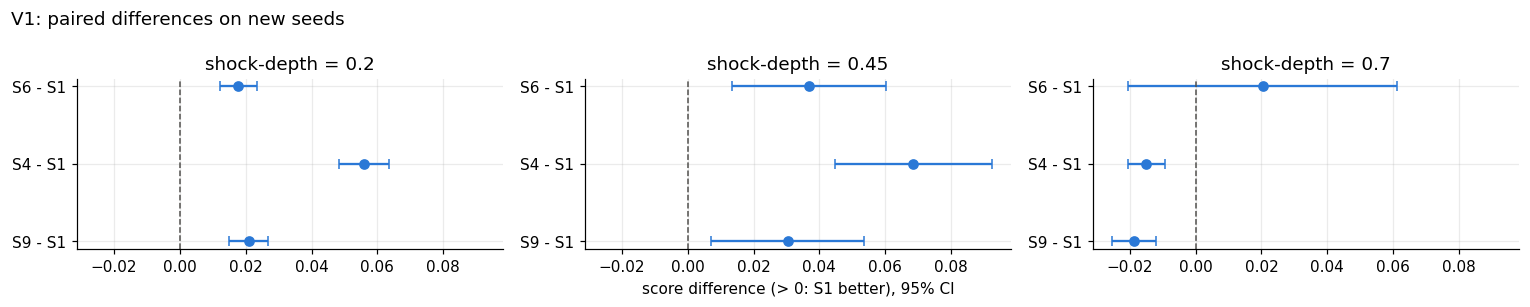

In [7]:
rows = []
w = V1.pivot_table(index=["shock", "seed"], columns="strategy", values=["score", "K0_rel", "K4_rel", "K5_excess", "COST"])
for sh in SHOCKS:
    for r in RIVALS:
        for m in ["score", "K0_rel", "K4_rel", "K5_excess", "COST"]:
            d = (w[(m, r)] - w[(m, ROBUST)]).loc[sh]
            rows.append({"shock": sh, "rival": r, "metric": m, "mean_diff": d.mean(), "ci95": ci95(d),
                         "robust_better_share": (d > 0).mean()})
PAIR = pd.DataFrame(rows)
PAIR["significant"] = (PAIR.mean_diff.abs() > PAIR.ci95)
PAIR.to_csv(OUT_DIR / "validation_v1_pairs.csv", index=False, encoding="utf-8-sig")
print(f"Paired differences on score (rival minus {ROBUST}; > 0 means {ROBUST} is better):")
display(PAIR[PAIR.metric == "score"].drop(columns="metric").round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 2.8), sharex=True)
for ax, sh in zip(axes, SHOCKS):
    d = PAIR[(PAIR.metric == "score") & (PAIR.shock == sh)]
    ax.errorbar(d.mean_diff, range(len(d)), xerr=d.ci95, fmt="o", color=PAL[0], capsize=3)
    ax.axvline(0, color="#52514e", lw=1, ls="--")
    ax.set_yticks(range(len(d)), [f"{r} - {ROBUST}" for r in d.rival]); ax.set_title(f"shock-depth = {sh}")
axes[1].set_xlabel(f"score difference (> 0: {ROBUST} better), 95% CI")
fig.suptitle("V1: paired differences on new seeds", x=0.01, ha="left"); plt.tight_layout(); plt.show()

## 5.5. V2: новые сценарии неопределённости

Те же метрики и правила ответов, что на этапе 3, но на 20 сценариях на шок, которых при выборе не было. Сравнение с этапом 3 - 90-й процентиль оценки и доля сценариев, где выполнены все пороги.


=== shock-depth = 0.2 ===


,score_mean,score_p90,regret_max,pass_share,K0_rel,K4_rel,K5_excess,COST,score_p90_stage3,pass_share_stage3
strategy,,,,,,,,,,
S1,0.145,0.222,0.151,0.95,0.013,0.191,1.017,70063.041,0.173,0.925
S2,0.162,0.229,0.099,0.95,0.021,0.078,1.173,100932.096,0.181,0.912
S3,0.153,0.223,0.117,0.90,0.023,0.185,1.317,66146.143,0.182,0.950
S4,0.194,0.265,0.124,0.95,0.018,0.121,0.599,150434.523,0.221,0.962
S5,0.224,0.376,0.299,0.75,0.062,0.206,2.333,108077.917,0.255,0.875
S6,0.178,0.260,0.182,0.90,0.026,0.187,1.320,92956.216,0.203,0.925
S7,0.414,0.500,0.425,0.00,0.009,0.011,2.089,364377.827,0.500,0.000
S8,0.153,0.233,0.086,0.95,0.004,0.141,0.695,98604.764,0.181,0.962
S9,0.175,0.254,0.182,0.90,0.016,0.189,1.287,93863.093,0.189,0.950



=== shock-depth = 0.45 ===


,score_mean,score_p90,regret_max,pass_share,K0_rel,K4_rel,K5_excess,COST,score_p90_stage3,pass_share_stage3
strategy,,,,,,,,,,
S1,0.179,0.226,0.089,0.55,0.125,0.160,2.422,185188.542,0.215,0.638
S2,0.238,0.376,0.167,0.30,0.225,0.039,6.797,191989.249,0.360,0.338
S3,0.391,0.583,0.450,0.15,0.569,0.115,35.735,124715.428,0.547,0.312
S4,0.226,0.351,0.246,0.55,0.129,0.293,2.807,196632.563,0.329,0.675
S5,0.373,0.570,0.462,0.30,0.516,0.187,39.438,106899.240,0.536,0.475
S6,0.200,0.278,0.187,0.40,0.123,0.275,5.142,142425.569,0.266,0.650
S7,0.336,0.448,0.301,0.00,0.036,0.142,4.234,414885.935,0.423,0.000
S8,0.206,0.281,0.132,0.70,0.095,0.077,3.507,224311.010,0.249,0.762
S9,0.211,0.267,0.151,0.65,0.084,0.304,4.104,162102.931,0.264,0.762



=== shock-depth = 0.7 ===


,score_mean,score_p90,regret_max,pass_share,K0_rel,K4_rel,K5_excess,COST,score_p90_stage3,pass_share_stage3
strategy,,,,,,,,,,
S1,0.207,0.220,0.060,0.20,0.176,0.145,9.493,268118.694,0.210,0.300
S2,0.434,0.509,0.321,0.00,2.331,0.024,134.355,195378.701,0.468,0.012
S3,0.553,0.592,0.449,0.00,3.454,0.069,181.917,126750.000,0.597,0.000
S4,0.222,0.301,0.160,0.15,0.190,0.272,29.986,191622.888,0.233,0.312
S5,0.557,0.579,0.427,0.00,3.289,0.112,189.633,99232.401,0.583,0.012
S6,0.292,0.440,0.238,0.05,0.562,0.233,83.804,144376.435,0.399,0.125
S7,0.289,0.306,0.168,0.00,0.041,0.162,9.463,412551.320,0.305,0.000
S8,0.222,0.235,0.064,0.00,0.155,0.049,10.863,333201.188,0.222,0.125
S9,0.218,0.261,0.272,0.25,0.115,0.436,14.667,166413.725,0.236,0.412


V2 answer 1 - best strategy for each shock (min P90 score):


,shock,strategy,score_p90,pass_share
1,0.20,S1,0.222,0.95
12,0.45,S1,0.226,0.55
23,0.70,S1,0.220,0.20


V2 answer 2 - single robust strategy: S1 (worst-shock P90 score 0.226)


,worst P90 score across shocks
strategy,
S1,0.226
S9,0.267
S8,0.281
S4,0.351
S6,0.440
S7,0.500
S2,0.509
S5,0.579
S3,0.592


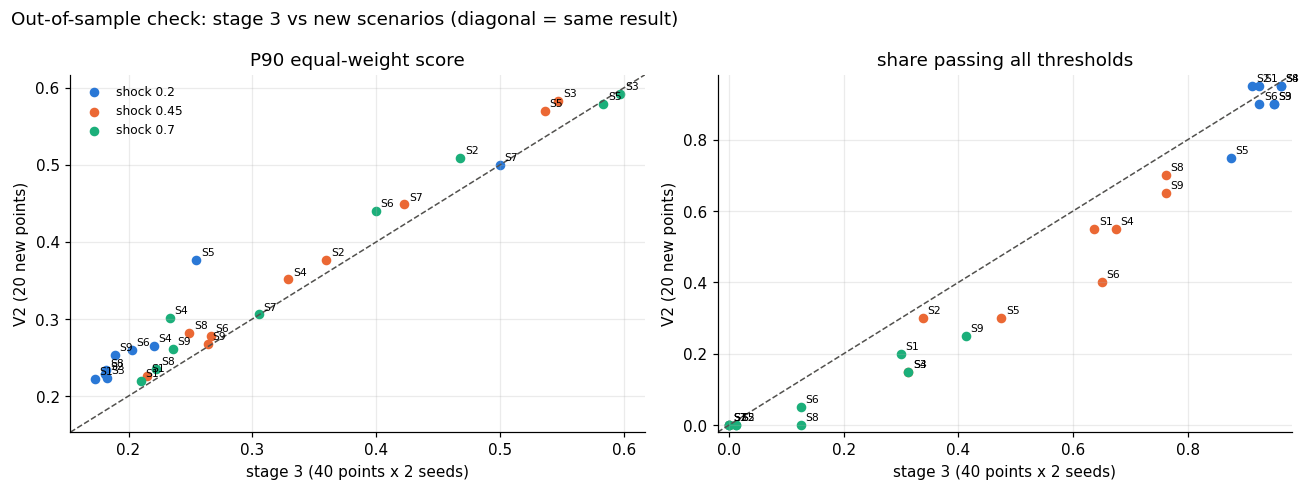

In [8]:
def p90(x):
    return np.quantile(x, 0.9)

T2 = V2.groupby(["shock", "strategy"]).agg(score_mean=("score", "mean"), score_p90=("score", p90),
                                            regret_max=("score_regret", "max"), pass_share=("pass_all", "mean"),
                                            K0_rel=("K0_rel", "mean"), K4_rel=("K4_rel", "mean"),
                                            K5_excess=("K5_excess", "mean"), COST=("COST", "mean")).reset_index()
cmp = ST3.set_index(["shock", "strategy"])[["score_p90", "pass_share"]].rename(columns=lambda c: c + "_stage3")
T2 = T2.join(cmp, on=["shock", "strategy"])
T2.to_csv(OUT_DIR / "validation_v2_table.csv", index=False, encoding="utf-8-sig")
for sh in SHOCKS:
    print(f"\n=== shock-depth = {sh} ===")
    display(T2[T2.shock == sh].drop(columns="shock").set_index("strategy").reindex(NAMES).round(3))

F2 = T2[T2.strategy.isin(FIN)]
ans1_v2 = F2.sort_values(["shock", "score_p90"]).groupby("shock").head(1)[["shock", "strategy", "score_p90", "pass_share"]]
worst_v2 = F2.groupby("strategy").score_p90.max().sort_values()
print("V2 answer 1 - best strategy for each shock (min P90 score):"); display(ans1_v2.round(3))
print(f"V2 answer 2 - single robust strategy: {worst_v2.index[0]} (worst-shock P90 score {worst_v2.iloc[0]:.3f})")
display(worst_v2.rename("worst P90 score across shocks").to_frame().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (m, lab) in zip(axes, [("score_p90", "P90 equal-weight score"), ("pass_share", "share passing all thresholds")]):
    for c, sh in zip(PAL, SHOCKS):
        d = F2[F2.shock == sh]
        ax.scatter(d[m + "_stage3"], d[m], color=c, s=28, label=f"shock {sh}")
        for r in d.itertuples():
            ax.annotate(r.strategy, (getattr(r, m + "_stage3"), getattr(r, m)), fontsize=7, xytext=(3, 3),
                        textcoords="offset points")
    lim = [min(F2[m].min(), F2[m + "_stage3"].min()) - 0.02, max(F2[m].max(), F2[m + "_stage3"].max()) + 0.02]
    ax.plot(lim, lim, color="#52514e", lw=1, ls="--"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"stage 3 (40 points x 2 seeds)"); ax.set_ylabel("V2 (20 new points)"); ax.set_title(lab)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Out-of-sample check: stage 3 vs new scenarios (diagonal = same result)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 5.6. Вердикт и итог этапа

Выводы этапа 3 считаются подтверждёнными, если: устойчивая стратегия остаётся лучшей по худшему 90-му процентилю в V2; при каждом шоке она лучшая или в пределах доверительного интервала от лучшей в V1; ранговая корреляция с этапом 3 высокая. Пришлите вывод этой ячейки, таблицы 5.4 и 5.5 и оба рисунка.

In [9]:
best_v1 = T1[T1.strategy.isin(FIN)].sort_values(["shock", "score_mean"]).groupby("shock").head(1).set_index("shock").strategy
rho = {sh: float(stats.spearmanr(T1[T1.shock == sh].rank_V1, T1[T1.shock == sh].rank_stage3).statistic) for sh in SHOCKS}
within_ci = {}
for sh in SHOCKS:
    b = best_v1[sh]
    if b == ROBUST:
        within_ci[sh] = True
    else:
        d = (w[("score", ROBUST)] - w[("score", b)]).loc[sh]
        within_ci[sh] = bool(d.mean() <= ci95(d))      # отставание S1 от лучшей статистически не отличимо от 0
checks = {
    "robust strategy unchanged in V2": worst_v2.index[0] == ROBUST,
    "robust strategy best or not significantly worse in V1 at every shock": all(within_ci.values()),
    "rank correlation with stage 3 >= 0.8 at every shock": all(v >= 0.8 for v in rho.values()),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
print("Best in V1 by shock:", best_v1.to_dict(), "| Spearman:", {k: round(v, 2) for k, v in rho.items()})

SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": sha, "seeds_v1": SEEDS_V1, "seed_v2": SEED_V2,
    "n_points_v2": N_V2, "robust_strategy_stage3": ROBUST, "rivals": RIVALS,
    "best_v1_by_shock": {str(k): v for k, v in best_v1.items()}, "spearman_v1_vs_stage3": {str(k): v for k, v in rho.items()},
    "answer_per_shock_v2": {str(r.shock): r.strategy for r in ans1_v2.itertuples()},
    "robust_strategy_v2": worst_v2.index[0], "checks": checks,
    "n_runs": {"v1": int(len(V1)), "v2": int(len(V2))},
}
(OUT_DIR / "validation_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(SUMMARY["checks"], indent=1))

PASS robust strategy unchanged in V2
FAIL robust strategy best or not significantly worse in V1 at every shock
PASS rank correlation with stage 3 >= 0.8 at every shock
Best in V1 by shock: {0.2: 'S3', 0.45: 'S1', 0.7: 'S9'} | Spearman: {0.2: 0.95, 0.45: 0.94, 0.7: 0.94}
{
 "robust strategy unchanged in V2": true,
 "robust strategy best or not significantly worse in V1 at every shock": false,
 "rank correlation with stage 3 >= 0.8 at every shock": true
}
